In [2]:
import matplotlib.pyplot as plt
import scipy.constants as c
import numpy as np
from utils import DoubleWellPotential, RingPolymerLangevin

kb = c.k
hbar = c.hbar


def run_simulation(
    n_steps: int = 50000,
    P: int = 32,
    gamma: float = None,
    alpha: float = 1 / 100,
    xc: float = None,
    C: float = 0.8,
    a: float = 0.04e-9,
    seed: int = 42,
):
    """Initialise le potentiel, configure la simulation et exécute la trajectoire."""
    mass = c.m_p
    V0 = hbar**2 / (2.0 * mass * a**2 * C)
    pot = DoubleWellPotential(V0, a)
    T = 0.2 * pot.V0 / kb

    print(f"--- Configuration ---")
    print(f"V0 = {pot.V0:.2e} J ({pot.V0 / c.e:.2f} eV) | T = {T:.2f} K")
    print(f"P = {P} | n_steps = {n_steps} | alpha = {alpha}")

    sim = RingPolymerLangevin(
        potential=pot,
        mass=mass,
        T=T,
        P=P,
        xc=xc,
        gamma=gamma,
        alpha=alpha,
        seed=seed,
    )
    print(f"dt = {sim.dt:.3e} s | gamma = {sim.gamma:.3e} s^-1")

    # Exécution de la dynamique
    res = sim.run(n_steps)
    print("Simulation terminée avec succès.")

    return sim, res

### 1 - Verification du modele (P=1, gamma=0)

--- Configuration ---
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1 | n_steps = 1000 | alpha = 0.01
dt = 1.008e-15 s | gamma = 0.000e+00 s^-1
Simulation terminée avec succès.


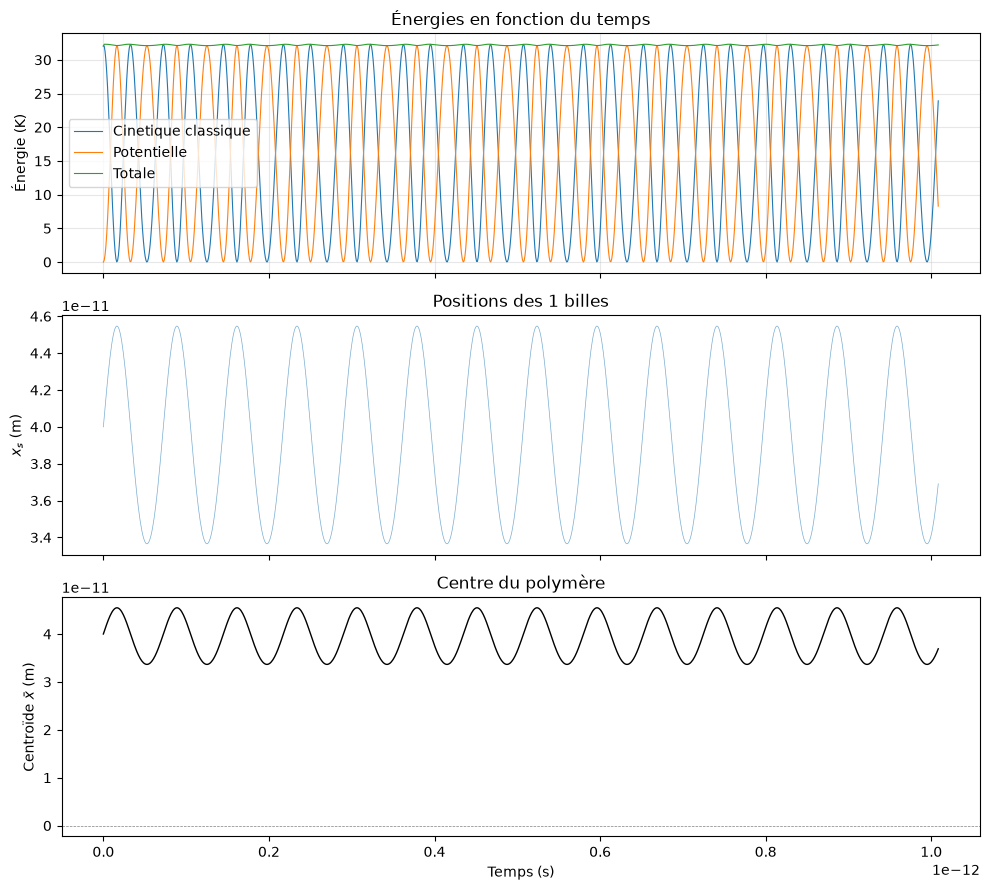

In [ ]:
# --- Simulation & resultats ---
sim, res = run_simulation(n_steps=1000, P=1, gamma=0, alpha=1/100, xc=None, seed=None)

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

axes[0].plot(res.t, res.e_kin_class_kelvin, label="Cinetique classique", lw=0.8)
axes[0].plot(res.t, res.e_pot_kelvin, label="Potentielle", lw=0.8)
axes[0].plot(res.t, res.e_pot_kelvin + res.e_kin_class_kelvin, label="Totale", lw=0.8)
axes[0].set_ylabel("Énergie (K)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_title("Énergies en fonction du temps")

axes[1].plot(res.t, res.X, lw=0.5, alpha=0.6)
axes[1].set_ylabel("$x_s$ (m)")
axes[1].set_title(f"Positions des {res.P} billes")

axes[2].plot(res.t, res.centroid, color="k", lw=1)
axes[2].axhline(0, color="gray", ls="--", lw=0.5)
axes[2].set_ylabel(r"Centroïde $\bar{x}$ (m)")
axes[2].set_xlabel("Temps (s)")
axes[2].set_title("Centre du polymère")

fig.tight_layout()
plt.show()

### 2 - Verification du thermostat

Question 3: On prend P=1 et on choisit les valeurs optimales du pas de temps et du coefficient de friction gamma.

--- Configuration ---
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1 | n_steps = 100000 | alpha = 0.01
dt = 1.008e-15 s | gamma = 9.916e+11 s^-1
Simulation terminée avec succès.


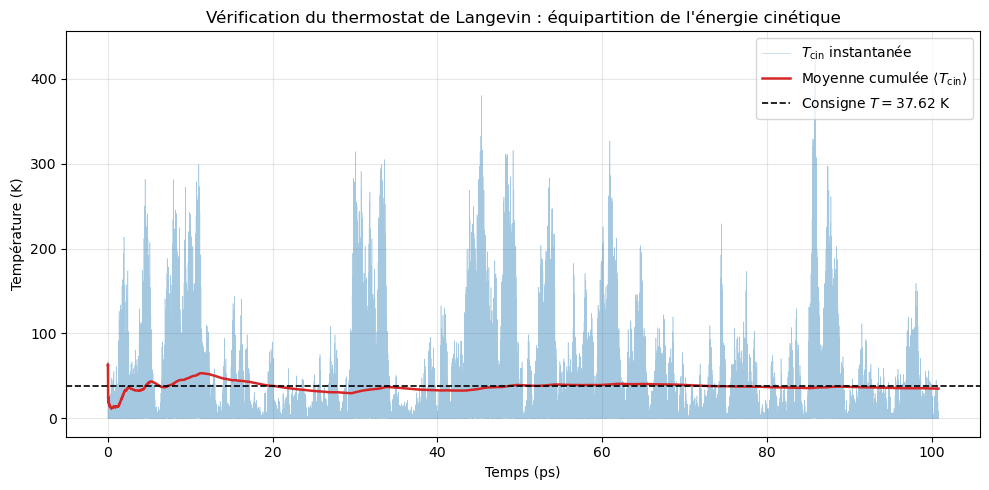

In [6]:
# --- Simulation & resultats ---
sim, res = run_simulation(n_steps=100000, P=1, gamma=None, alpha=1/100, xc=None, seed=None)
t_instantanee = res.e_kin_class_kelvin
t_cumulee = np.cumsum(t_instantanee) / np.arange(1, len(t_instantanee) + 1)

# fig, ax au lieu de fig, axes
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(res.t * 1e12, t_instantanee, color="tab:blue", lw=0.4, alpha=0.4, label=r"$T_{\mathrm{cin}}$ instantanée")
ax.plot(res.t * 1e12, t_cumulee, color="tab:red", lw=1.8, label=r"Moyenne cumulée $\langle T_{\mathrm{cin}} \rangle$")
ax.axhline(sim.T, color="black", ls="--", lw=1.2, label=f"Consigne $T = {sim.T:.2f}$ K")

ax.set_xlabel("Temps (ps)")
ax.set_ylabel("Température (K)")
ax.legend(loc="upper right")
ax.grid(True, alpha=0.3)
ax.set_title("Vérification du thermostat de Langevin : équipartition de l'énergie cinétique")

fig.tight_layout()
plt.show()

### Question 4

---------- Simulation pour P=1 ----------
--- Configuration ---
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1 | n_steps = 100000 | alpha = 0.01
dt = 1.008e-15 s | gamma = 9.916e+11 s^-1
Simulation terminée avec succès.
---------- Simulation pour P=2 ----------
--- Configuration ---
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 2 | n_steps = 100000 | alpha = 0.01
dt = 1.008e-15 s | gamma = 9.916e+11 s^-1
Simulation terminée avec succès.
---------- Simulation pour P=4 ----------
--- Configuration ---
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 4 | n_steps = 100000 | alpha = 0.01
dt = 1.008e-15 s | gamma = 9.916e+11 s^-1
Simulation terminée avec succès.
---------- Simulation pour P=8 ----------
--- Configuration ---
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 8 | n_steps = 100000 | alpha = 0.01
dt = 1.008e-15 s | gamma = 9.916e+11 s^-1
Simulation terminée avec succès.
---------- Simulation pour P=16 ----------
--- Configuration ---
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 16 | n_steps = 

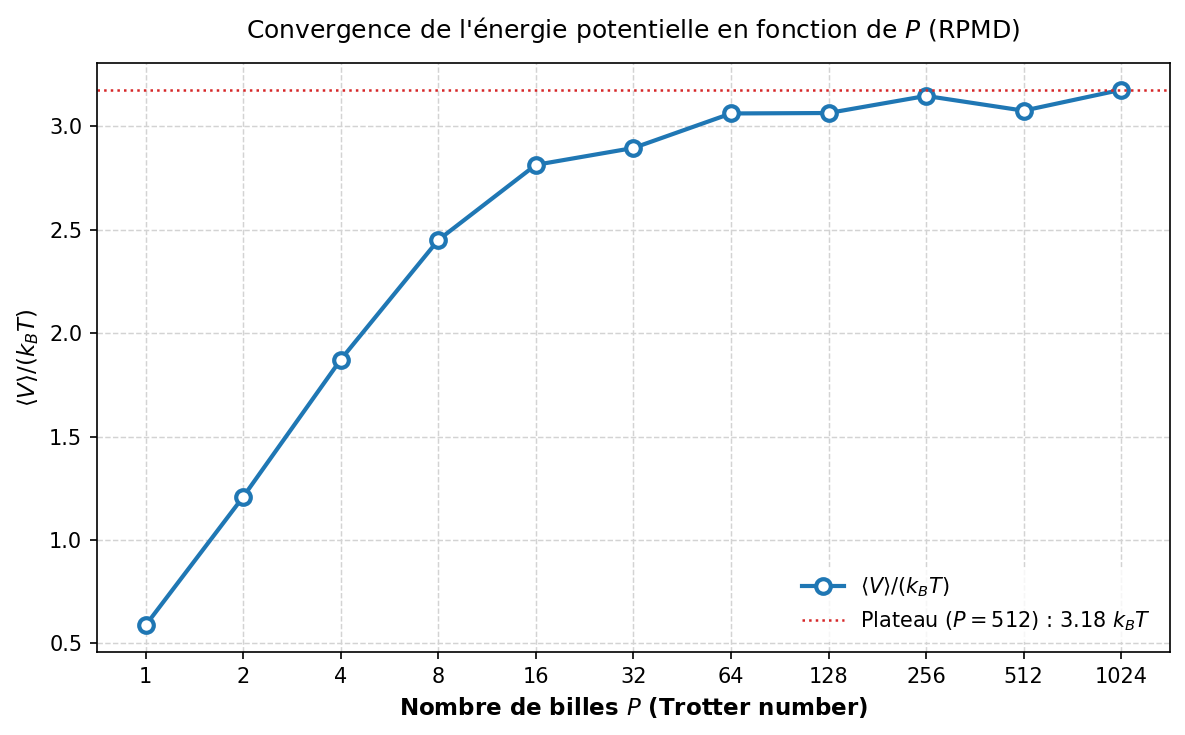

In [8]:
import matplotlib.pyplot as plt
import numpy as np

list_P = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]
e_pot_mean = []
e_pot_std = []  # Pour barre d'erreur ou incertitude statistique

for p in list_P:
    print(f"---------- Simulation pour P={p} ----------")
    sim, res = run_simulation(
        n_steps=100000, P=p, gamma=None, alpha=1 / 100, xc=None, seed=None
    )

    # On écarte la première moitié (ou 20 000 pas) pour moyenner à l'équilibre
    eq_start = len(res.e_pot) // 2
    e_pot_equil = res.e_pot[eq_start:]

    # Conversion en Kelvin (ou en unités de k_B * T)
    e_pot_mean.append(np.mean(e_pot_equil) / (kb * sim.T))

# --- Tracé esthétique ---
fig, ax = plt.subplots(figsize=(8, 5), dpi=150)

# Tracé principal avec marqueurs stylisés
ax.plot(
    list_P,
    e_pot_mean,
    marker="o",
    markersize=7,
    markerfacecolor="white",
    markeredgewidth=2,
    markeredgecolor="#1f77b4",
    linewidth=2,
    color="#1f77b4",
    label=r"$\langle V \rangle / (k_B T)$",
)

# Échelle log base 2 pour P
ax.set_xscale("log", base=2)
ax.set_xticks(list_P)
ax.set_xticklabels([str(p) for p in list_P])

# Labels et mise en page
ax.set_xlabel(r"Nombre de billes $P$ (Trotter number)", fontsize=11, fontweight="bold")
ax.set_ylabel(r"$\langle V \rangle / (k_B T)$", fontsize=11, fontweight="bold")
ax.set_title(
    r"Convergence de l'énergie potentielle en fonction de $P$ (RPMD)",
    fontsize=12,
    pad=12,
)

# Grille subtile
ax.grid(True, which="major", color="#d3d3d3", linestyle="--", linewidth=0.7)
ax.grid(True, which="minor", color="#f0f0f0", linestyle=":", linewidth=0.5)

# Valeur asymptotique estimée (plateau à grand P)
val_plateau = e_pot_mean[-1]
ax.axhline(
    val_plateau,
    color="#d62728",
    linestyle=":",
    linewidth=1.2,
    label=f"Plateau ($P=512$) : {val_plateau:.2f} $k_B T$",
)

ax.legend(frameon=True, facecolor="white", edgecolor="none", fontsize=10)
fig.tight_layout()
plt.show()

### Question 5

--- Configuration ---
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 100 | n_steps = 10000 | alpha = 0.01
dt = 1.276e-16 s | gamma = 7.840e+12 s^-1
Simulation terminée avec succès.


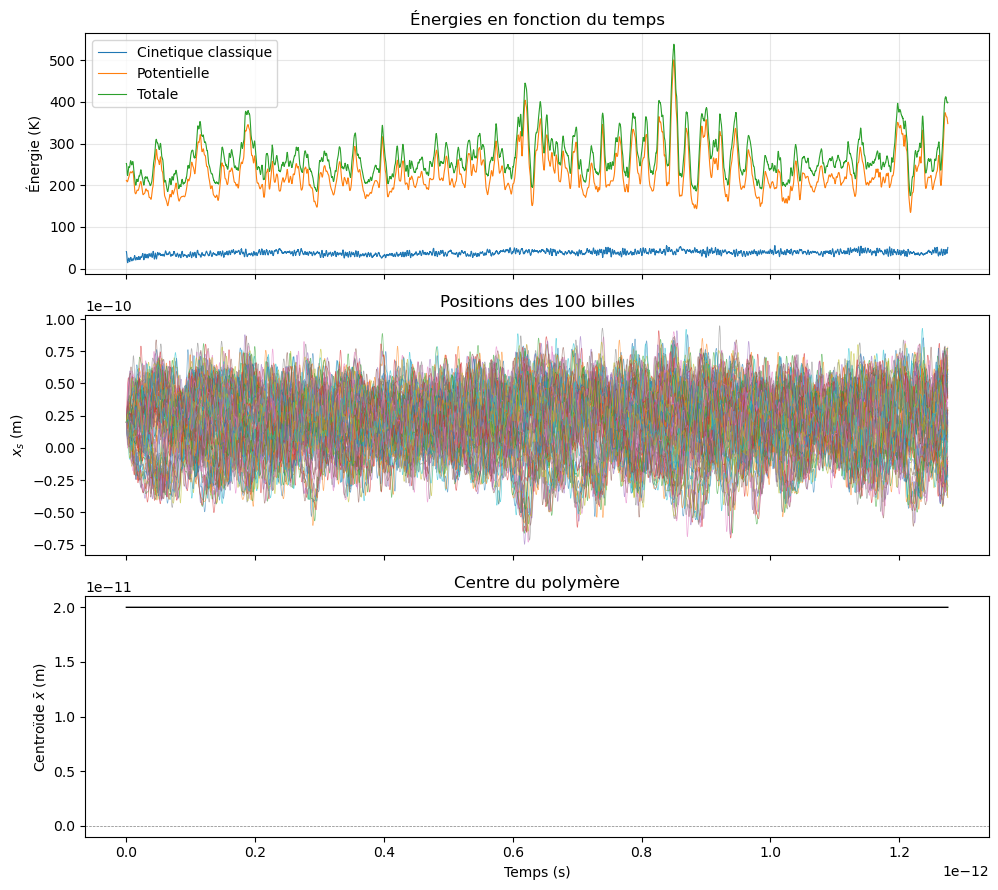

Centroïde moyenne: 2.00e-01 Angström
Centroïde écart-type: 9.52e-14 Angström


In [12]:
# --- Simulation & resultats ---
sim, res = run_simulation(n_steps=10000, P=100, gamma=None, alpha=1/100, xc=0.02e-9, seed=None)

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

axes[0].plot(res.t, res.e_kin_class_kelvin, label="Cinetique classique", lw=0.8)
axes[0].plot(res.t, res.e_pot_kelvin, label="Potentielle", lw=0.8)
axes[0].plot(res.t, res.e_pot_kelvin + res.e_kin_class_kelvin, label="Totale", lw=0.8)
axes[0].set_ylabel("Énergie (K)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_title("Énergies en fonction du temps")

axes[1].plot(res.t, res.X, lw=0.5, alpha=0.6)
axes[1].set_ylabel("$x_s$ (m)")
axes[1].set_title(f"Positions des {res.P} billes")

axes[2].plot(res.t, res.centroid, color="k", lw=1)
axes[2].axhline(0, color="gray", ls="--", lw=0.5)
axes[2].set_ylabel(r"Centroïde $\bar{x}$ (m)")
axes[2].set_xlabel("Temps (s)")
axes[2].set_title("Centre du polymère")

fig.tight_layout()
plt.show()
print(f"Centroïde moyenne: {(np.mean(res.centroid)*1e10):.2e} Angström")
print(f"Centroïde écart-type: {(np.std(res.centroid)*1e10):.2e} Angström")